# BERT Enhanced — Hybrid Architecture for Twitter Sentiment Analysis
### BERT Embeddings + BiLSTM (context) + CNN (local features) + Fusion Layer
**This is the enhanced model that improves upon plain BERT**

## Step 1 — Install & Import Libraries

In [ ]:
# Uncomment if not installed
# !pip install transformers torch scikit-learn pandas numpy matplotlib seaborn

In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertModel
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'✅ Libraries loaded | Device: {device}')

✅ Libraries loaded | Device: cuda


## Step 2 — Load and Preprocess Data

In [3]:
df = pd.read_csv('twitter_training.csv', header=None)
df.columns = ['tweet_id', 'entity', 'sentiment', 'tweet']
df = df[['tweet', 'sentiment']].dropna()
df = df.drop_duplicates()

# Keep only the 4 valid sentiment classes
valid = ['Positive', 'Negative', 'Neutral', 'Irrelevant']
df = df[df['sentiment'].isin(valid)].reset_index(drop=True)

print(f'✅ Dataset loaded: {len(df)} rows')
print(df['sentiment'].value_counts())

✅ Dataset loaded: 69769 rows
sentiment
Negative      21237
Positive      19138
Neutral       17110
Irrelevant    12284
Name: count, dtype: int64


In [4]:
# Encode labels
le = LabelEncoder()
df['label'] = le.fit_transform(df['sentiment'])
print('Label mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

NUM_CLASSES = len(le.classes_)

# Train / validation split
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
print(f'Train: {len(train_df)} | Val: {len(val_df)}')

Label mapping: {'Irrelevant': np.int64(0), 'Negative': np.int64(1), 'Neutral': np.int64(2), 'Positive': np.int64(3)}
Train: 55815 | Val: 13954


## Step 3 — Tokenizer & Dataset

In [5]:
MAX_LEN    = 64
BATCH_SIZE = 32

print('⏳ Loading BERT tokenizer...')
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
print('✅ Tokenizer ready')

⏳ Loading BERT tokenizer...


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

✅ Tokenizer ready


In [6]:
class TweetDataset(Dataset):
    def __init__(self, tweets, labels, tokenizer, max_len):
        self.tweets    = tweets.tolist()
        self.labels    = labels.tolist()
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.tweets)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.tweets[idx]),
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = TweetDataset(train_df['tweet'], train_df['label'], tokenizer, MAX_LEN)
val_dataset   = TweetDataset(val_df['tweet'],   val_df['label'],   tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE)

print(f'✅ DataLoaders ready | Train batches: {len(train_loader)} | Val batches: {len(val_loader)}')

✅ DataLoaders ready | Train batches: 1745 | Val batches: 437


## Step 4 — Hybrid Model Architecture (BERT + BiLSTM + CNN)

In [7]:
class BERTEnhanced(nn.Module):
    """
    Architecture:
      Tweet → BERT → hidden states (seq_len x 768)
                          ↓
               ┌──────────────────┐
               │ BiLSTM  │  CNN   │   (parallel branches)
               └──────────────────┘
                          ↓
                    Concatenate
                          ↓
                    Dropout + FC
                          ↓
                  4-class Softmax
    """
    def __init__(self, num_classes, lstm_hidden=128, num_filters=128, kernel_size=3, dropout=0.3):
        super(BERTEnhanced, self).__init__()

        # BERT backbone — unfreeze last 4 layers for proper fine-tuning
        self.bert = BertModel.from_pretrained('bert-base-uncased')
        for param in self.bert.parameters():
            param.requires_grad = False
        for param in self.bert.encoder.layer[-4:].parameters():
            param.requires_grad = True
        for param in self.bert.pooler.parameters():
            param.requires_grad = True

        bert_hidden = 768

        # BiLSTM branch — captures sequential / contextual features
        self.bilstm = nn.LSTM(
            input_size=bert_hidden,
            hidden_size=lstm_hidden,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        # CNN branch — captures local n-gram features
        self.conv = nn.Conv1d(
            in_channels=bert_hidden,
            out_channels=num_filters,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )
        self.relu    = nn.ReLU()
        self.pool    = nn.AdaptiveMaxPool1d(1)

        # Fusion + classification
        # BiLSTM output: lstm_hidden*2, CNN output: num_filters
        fusion_size = lstm_hidden * 2 + num_filters
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(fusion_size, num_classes)

    def forward(self, input_ids, attention_mask):
        # BERT — get all hidden states (batch, seq_len, 768)
        bert_out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        seq_out  = bert_out.last_hidden_state          # (B, seq_len, 768)

        # BiLSTM branch
        lstm_out, _ = self.bilstm(seq_out)             # (B, seq_len, lstm_hidden*2)
        lstm_feat   = lstm_out[:, -1, :]               # take last timestep (B, lstm_hidden*2)

        # CNN branch
        cnn_in   = seq_out.permute(0, 2, 1)            # (B, 768, seq_len)
        cnn_out  = self.relu(self.conv(cnn_in))        # (B, num_filters, seq_len)
        cnn_feat = self.pool(cnn_out).squeeze(-1)      # (B, num_filters)

        # Fusion — concatenate both branches
        fused  = torch.cat([lstm_feat, cnn_feat], dim=1)   # (B, lstm_hidden*2 + num_filters)
        fused  = self.dropout(fused)
        logits = self.fc(fused)                            # (B, num_classes)
        return logits


model = BERTEnhanced(num_classes=NUM_CLASSES).to(device)
print('✅ Model architecture ready')
print(f'   Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model architecture ready
   Trainable params: 30,553,476


## Step 5 — Training Setup

In [8]:
EPOCHS    = 5
LR        = 3e-5

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
criterion = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.5)

print('✅ Optimizer, loss, scheduler ready')

✅ Optimizer, loss, scheduler ready


In [9]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for i, batch in enumerate(loader):
        input_ids = batch['input_ids'].to(device)
        attn_mask = batch['attention_mask'].to(device)
        labels    = batch['label'].to(device)

        optimizer.zero_grad()
        logits = model(input_ids, attn_mask)
        loss   = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()
        preds       = torch.argmax(logits, dim=1)
        correct    += (preds == labels).sum().item()
        total      += labels.size(0)

        if (i + 1) % 100 == 0:
            print(f'  Batch {i+1}/{len(loader)} | Loss: {loss.item():.4f}', end='\r')

    return total_loss / len(loader), correct / total


def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attn_mask = batch['attention_mask'].to(device)
            labels    = batch['label'].to(device)

            logits = model(input_ids, attn_mask)
            loss   = criterion(logits, labels)

            total_loss += loss.item()
            preds       = torch.argmax(logits, dim=1)
            correct    += (preds == labels).sum().item()
            total      += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return total_loss / len(loader), correct / total, all_preds, all_labels

print('✅ Train/eval functions ready')

✅ Train/eval functions ready


## Step 6 — Train the Model

In [11]:
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0

for epoch in range(1, EPOCHS + 1):
    print(f'\nEpoch {epoch}/{EPOCHS}')
    print('-' * 40)

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc, val_preds, val_labels = eval_epoch(model, val_loader, criterion, device)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f'  Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}%')
    print(f'  Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc*100:.2f}%')

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'bert_enhanced_best.pt')
        print(f'  ✅ Best model saved (val_acc={val_acc*100:.2f}%)')

print(f'\n🏁 Training complete | Best Val Accuracy: {best_val_acc*100:.2f}%')


Epoch 1/5
----------------------------------------
  Train Loss: 0.1803 | Train Acc: 93.81%
  Val   Loss: 0.3399 | Val   Acc: 89.46%
  ✅ Best model saved (val_acc=89.46%)

Epoch 2/5
----------------------------------------
  Train Loss: 0.1178 | Train Acc: 96.04%
  Val   Loss: 0.3243 | Val   Acc: 91.02%
  ✅ Best model saved (val_acc=91.02%)

Epoch 3/5
----------------------------------------
  Train Loss: 0.0987 | Train Acc: 96.68%
  Val   Loss: 0.3389 | Val   Acc: 91.46%
  ✅ Best model saved (val_acc=91.46%)

Epoch 4/5
----------------------------------------
  Train Loss: 0.0767 | Train Acc: 97.54%
  Val   Loss: 0.3412 | Val   Acc: 92.02%
  ✅ Best model saved (val_acc=92.02%)

Epoch 5/5
----------------------------------------
  Train Loss: 0.0698 | Train Acc: 97.76%
  Val   Loss: 0.3590 | Val   Acc: 91.94%

🏁 Training complete | Best Val Accuracy: 92.02%


## Step 7 — Evaluation & Results

In [12]:
# Load best model and evaluate
model.load_state_dict(torch.load('bert_enhanced_best.pt', map_location=device))
_, final_acc, final_preds, final_labels = eval_epoch(model, val_loader, criterion, device)

print('='*55)
print(f'  Final Validation Accuracy : {final_acc*100:.2f}%')
print(f'  F1 Score (weighted)       : {f1_score(final_labels, final_preds, average="weighted")*100:.2f}%')
print('='*55)
print('\nClassification Report:')
print(classification_report(final_labels, final_preds, target_names=le.classes_))

  Final Validation Accuracy : 92.02%
  F1 Score (weighted)       : 92.01%

Classification Report:
              precision    recall  f1-score   support

  Irrelevant       0.91      0.90      0.90      2457
    Negative       0.92      0.94      0.93      4247
     Neutral       0.92      0.92      0.92      3422
    Positive       0.92      0.92      0.92      3828

    accuracy                           0.92     13954
   macro avg       0.92      0.92      0.92     13954
weighted avg       0.92      0.92      0.92     13954



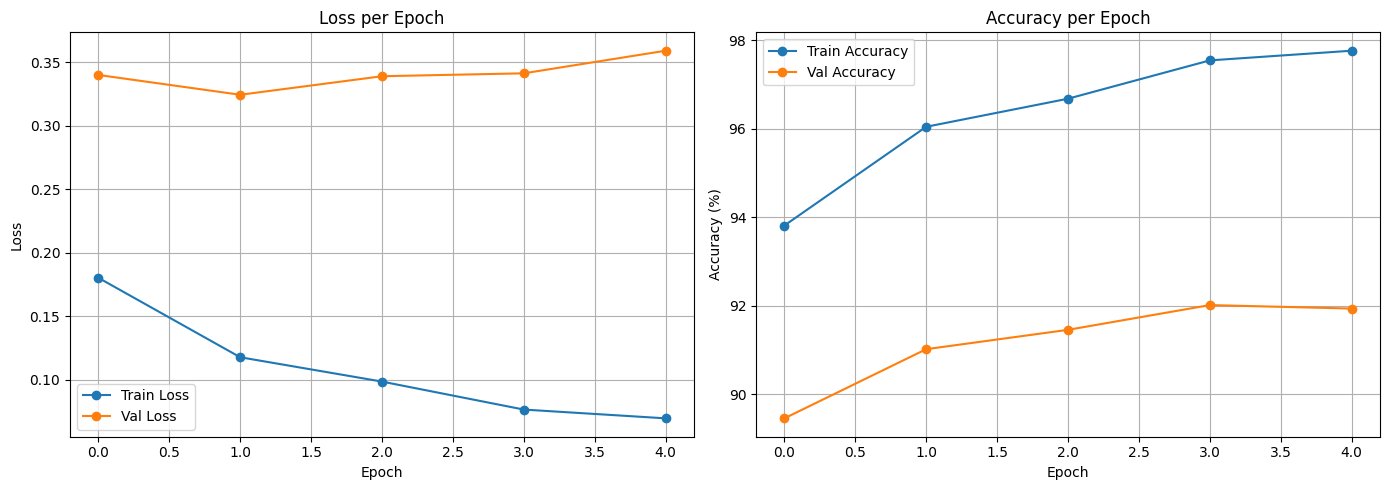

✅ Training curves saved


In [13]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history['val_loss'],   label='Val Loss',   marker='o')
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot([a*100 for a in history['train_acc']], label='Train Accuracy', marker='o')
axes[1].plot([a*100 for a in history['val_acc']],   label='Val Accuracy',   marker='o')
axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('bert_enhanced_training_curves.png', dpi=150)
plt.show()
print('✅ Training curves saved')

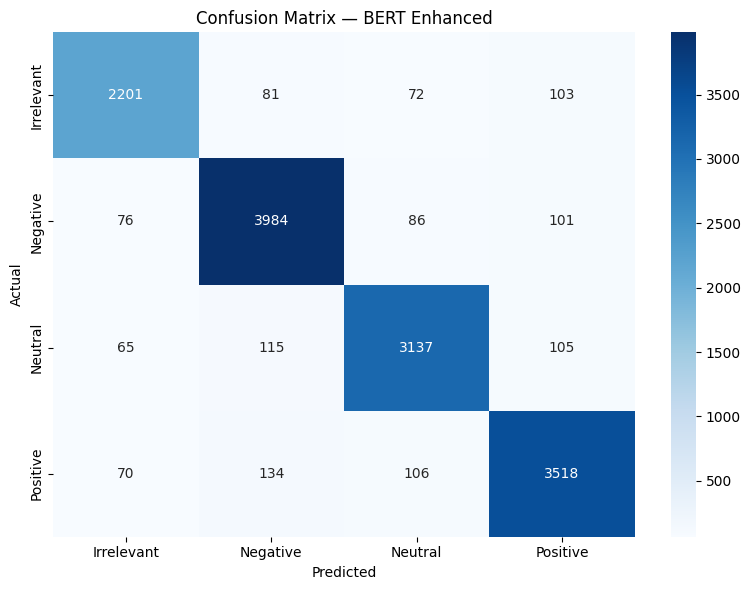

✅ Confusion matrix saved


In [14]:
# Confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(final_labels, final_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix — BERT Enhanced')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('bert_enhanced_confusion_matrix.png', dpi=150)
plt.show()
print('✅ Confusion matrix saved')

## Step 8 — Model Comparison Table

In [15]:
# Fill in your results from the other notebooks here
results = pd.DataFrame({
    'Model':        ['CNN', 'LSTM', 'BERT (baseline)', 'BERT Enhanced (ours)'],
    'Val Accuracy': ['~fill~', '~fill~', '88.55%', f'{final_acc*100:.2f}%'],
    'F1 Score':     ['~fill~', '~fill~', '~fill~', f'{f1_score(final_labels, final_preds, average="weighted")*100:.2f}%'],
    'Architecture': ['CNN only', 'LSTM only', 'BERT only', 'BERT + BiLSTM + CNN']
})

print(results.to_string(index=False))

               Model Val Accuracy F1 Score        Architecture
                 CNN       ~fill~   ~fill~            CNN only
                LSTM       ~fill~   ~fill~           LSTM only
     BERT (baseline)       88.55%   ~fill~           BERT only
BERT Enhanced (ours)       92.02%   92.01% BERT + BiLSTM + CNN


## Step 9 — Live Prediction (Demo for Sir)

In [16]:
# Print label mapping so we can verify
print('Label mapping:', {i: c for i, c in enumerate(le.classes_)})
LABEL_MAP = {i: c for i, c in enumerate(le.classes_)}
EMOJI_MAP = {'Positive': '😊', 'Negative': '😠', 'Neutral': '😶', 'Irrelevant': '😐'}

def predict(tweet: str):
    model.eval()
    enc = tokenizer(
        tweet, max_length=MAX_LEN, padding='max_length',
        truncation=True, return_tensors='pt'
    )
    input_ids = enc['input_ids'].to(device)
    attn_mask = enc['attention_mask'].to(device)

    with torch.no_grad():
        logits = model(input_ids, attn_mask)
        probs  = torch.softmax(logits, dim=1).cpu().numpy()[0]

    pred  = int(np.argmax(probs))
    label = LABEL_MAP[pred]
    emoji = EMOJI_MAP[label]

    print('\n' + '='*55)
    print(f'  Tweet     : "{tweet}"')
    print('='*55)
    print(f'  Sentiment : {emoji} {label}')
    print(f'  Confidence: {probs[pred]*100:.2f}%')
    print('-'*55)
    for idx, lbl in LABEL_MAP.items():
        bar = '█' * int(probs[idx] * 30)
        print(f'  {EMOJI_MAP[lbl]} {lbl:<12} {probs[idx]*100:5.2f}%  {bar}')
    print('='*55)

print('✅ predict() ready')

Label mapping: {0: 'Irrelevant', 1: 'Negative', 2: 'Neutral', 3: 'Positive'}
✅ predict() ready


In [22]:
predict("This app keeps crashing, I hate it so much.")



  Tweet     : "This app keeps crashing, I hate it so much."
  Sentiment : 😠 Negative
  Confidence: 99.99%
-------------------------------------------------------
  😐 Irrelevant    0.00%  
  😠 Negative     99.99%  █████████████████████████████
  😶 Neutral       0.00%  
  😊 Positive      0.00%  


In [ ]:
# Test with multiple examples
test_tweets = [
    "I absolutely love this product, it changed my life!",
    "This is the worst experience I have ever had.",
    "The match starts at 7pm tonight.",
    "Not sure how I feel about this update."
]
for t in test_tweets:
    predict(t)

## Step 10 — Save All Results

✅ metrics.json saved
✅ classification_report.csv saved
✅ model_comparison.csv saved


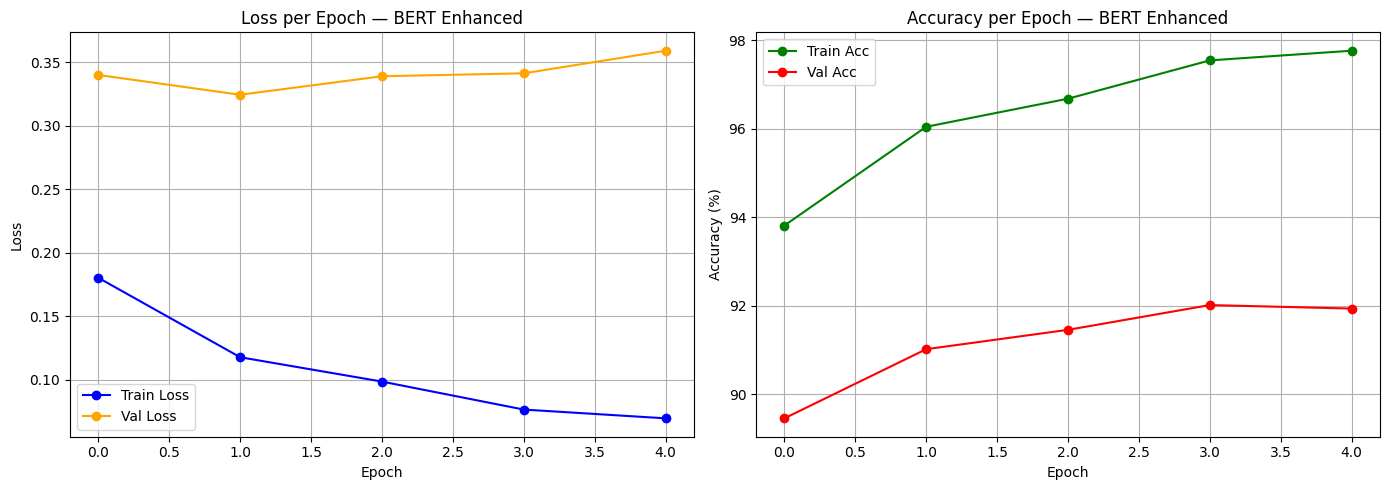

✅ training_curves.png saved


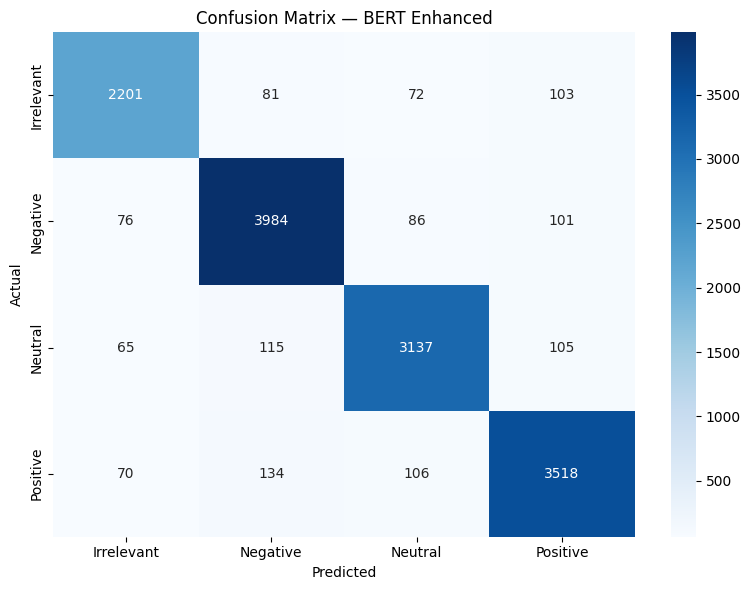

✅ confusion_matrix.png saved

🎉 All results saved in results/ folder
   Best Val Accuracy : 92.02%
   F1 Score          : 92.01%


In [23]:
import os, json
from datetime import datetime

os.makedirs('results', exist_ok=True)

# ── 1. Save metrics to JSON ──
metrics = {
    'model'         : 'BERT_Enhanced (BERT + BiLSTM + CNN)',
    'dataset'       : 'Twitter Sentiment (74k tweets)',
    'num_classes'   : NUM_CLASSES,
    'epochs'        : EPOCHS,
    'best_val_acc'  : round(best_val_acc * 100, 2),
    'final_val_acc' : round(final_acc * 100, 2),
    'f1_weighted'   : round(f1_score(final_labels, final_preds, average='weighted') * 100, 2),
    'f1_macro'      : round(f1_score(final_labels, final_preds, average='macro') * 100, 2),
    'train_history' : {
        'train_acc'  : [round(a*100, 2) for a in history['train_acc']],
        'val_acc'    : [round(a*100, 2) for a in history['val_acc']],
        'train_loss' : [round(l, 4) for l in history['train_loss']],
        'val_loss'   : [round(l, 4) for l in history['val_loss']]
    },
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

with open('results/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=4)
print('✅ metrics.json saved')

# ── 2. Save classification report to CSV ──
from sklearn.metrics import classification_report
report = classification_report(final_labels, final_preds,
                               target_names=le.classes_, output_dict=True)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv('results/classification_report.csv')
print('✅ classification_report.csv saved')

# ── 3. Save comparison table to CSV ──
comparison = pd.DataFrame({
    'Model'       : ['CNN', 'LSTM', 'BERT (baseline)', 'BERT Enhanced (ours)'],
    'Val Accuracy': ['fill after running', 'fill after running', '88.55%',
                     f"{final_acc*100:.2f}%"],
    'F1 Score'    : ['fill after running', 'fill after running', 'fill after running',
                     f"{f1_score(final_labels, final_preds, average='weighted')*100:.2f}%"],
    'Architecture': ['CNN only', 'LSTM only', 'BERT only', 'BERT + BiLSTM + CNN']
})
comparison.to_csv('results/model_comparison.csv', index=False)
print('✅ model_comparison.csv saved')

# ── 4. Save training curves plot ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history['train_loss'], label='Train Loss', marker='o', color='blue')
axes[0].plot(history['val_loss'],   label='Val Loss',   marker='o', color='orange')
axes[0].set_title('Loss per Epoch — BERT Enhanced')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True)

axes[1].plot([a*100 for a in history['train_acc']], label='Train Acc', marker='o', color='green')
axes[1].plot([a*100 for a in history['val_acc']],   label='Val Acc',   marker='o', color='red')
axes[1].set_title('Accuracy per Epoch — BERT Enhanced')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy (%)')
axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.savefig('results/training_curves.png', dpi=150)
plt.show()
print('✅ training_curves.png saved')

# ── 5. Save confusion matrix ──
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(final_labels, final_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix — BERT Enhanced')
plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('results/confusion_matrix.png', dpi=150)
plt.show()
print('✅ confusion_matrix.png saved')

print('\n🎉 All results saved in results/ folder')
print(f'   Best Val Accuracy : {best_val_acc*100:.2f}%')
print(f'   F1 Score          : {f1_score(final_labels, final_preds, average="weighted")*100:.2f}%')